In [12]:
import pyarrow.parquet as pq
import os
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
# Optional, for more advanced analysis - install if needed
# from sklearn.feature_extraction.text import TfidfVectorizer
# from sklearn.cluster import KMeans
# from sklearn.manifold import TSNE
# from mlxtend.frequent_patterns import apriori, association_rules


def read_parquet_as_df(parquet_path: str):
    return pq.read_table(parquet_path).to_pandas()

In [ ]:
print(read_parquet_as_df(r"/workspace/qgi\qgi-4.0\data\indicator_extractors\wb\MS.MIL.MPRT.KD\MS.MIL.MPRT.KD.parquet"))

        country  year       value
0         Aruba  1960         NaN
1         Aruba  1961         NaN
2         Aruba  1962         NaN
3         Aruba  1963         NaN
4         Aruba  1964         NaN
...         ...   ...         ...
17019  Zimbabwe  2019         NaN
17020  Zimbabwe  2020         NaN
17021  Zimbabwe  2021         NaN
17022  Zimbabwe  2022         NaN
17023  Zimbabwe  2023  20000000.0

[13760 rows x 3 columns]


In [16]:
print(read_parquet_as_df(r"/workspace/qgi\qgi-4.0\data\scdi_finder_output\IT.NET.USER.ZS\Denmark.parquet"))

        country_a_id  country_b_id  length  start_year_a  start_year_b  \
0                 58            62       3          1990          1990   
1                 58            62       3          1990          1991   
2                 58            62       3          1990          1992   
3                 58            62       3          1990          1993   
4                 58            62       3          1990          1994   
...              ...           ...     ...           ...           ...   
333477            58           221      34          1991          1991   
333478            58           236      34          1991          1990   
333479            58           236      34          1991          1991   
333480            58           206      34          1991          1990   
333481            58           206      34          1991          1991   

        correlation  
0          0.982077  
1          0.987343  
2          0.998649  
3          0.926742  
4

In [17]:
print(read_parquet_as_df(r"/workspace/qgi\qgi-4.0\data\pattern_maker_output\Australia\patterns_Australia.parquet"))

       country_a_id  country_b_id  length  start_year_a  start_year_b  \
0                13            14       3          1960          1960   
1                13            14       3          1960          1961   
2                13            14       3          1960          1968   
3                13            14       3          1960          1969   
4                13            14       3          1960          1977   
...             ...           ...     ...           ...           ...   
77999            13             1       5          2015          1982   
78000            13             1       5          2016          1982   
78001            13             1       5          2018          1982   
78002            13             1       5          1963          1983   
78003            13             1       5          2014          1983   

       average_correlation  scdi_count  
0                 0.950012           7  
1                 0.885659           5  


In [18]:
df = read_parquet_as_df(r"/workspace/qgi\qgi-4.0\data\recipes\economic_growth.parquet")
print(df)

            indicator_name country_name  scdi_row_index  correlation
0        EG.ELC.ACCS.RU.ZS            2             177     0.866025
1        EG.ELC.ACCS.RU.ZS            2             197     0.500000
2        EG.ELC.ACCS.RU.ZS            2             209     0.866025
3        EG.ELC.ACCS.RU.ZS            2             214     0.777714
4        EG.ELC.ACCS.RU.ZS            2             235     0.866025
...                    ...          ...             ...          ...
2522326        SP.POP.TOTL      Vietnam          435904     0.972026
2522327        SP.POP.TOTL      Vietnam          440983     0.969523
2522328        SP.POP.TOTL      Vietnam          445720     0.967038
2522329        SP.POP.TOTL      Vietnam          450127     0.964653
2522330        SP.POP.TOTL      Vietnam          454216     0.962387

[2522331 rows x 4 columns]


In [3]:
class RecipeAnalyzer:
    """
    A class dedicated to loading, analyzing, and discovering insights
    from recipe Parquet files generated by the EventRecipeGenerator.
    """

    def __init__(self, recipes_path, countries_csv_path=None):
        """
        Initializes the RecipeAnalyzer.

        Args:
            recipes_path (str): Path to the directory containing recipe Parquet files.
            countries_csv_path (str, optional): Path to the countries.csv file for
                                                potential data enrichment or mapping.
        """
        self.recipes_path = recipes_path
        if not os.path.exists(self.recipes_path):
            print(f"Warning: Recipes path does not exist: {self.recipes_path}")
            # Consider raising an error or handling more gracefully if path is critical for all methods
        
        self.countries_df = None
        if countries_csv_path:
            try:
                if os.path.exists(countries_csv_path):
                    self.countries_df = pd.read_csv(countries_csv_path)
                else:
                    print(f"Warning: Countries CSV path does not exist: {countries_csv_path}")
            except Exception as e:
                print(f"Warning: Could not load countries CSV from {countries_csv_path}: {e}")
        
        self.all_recipes_concatenated_df = self._load_all_recipes()

    def _sanitize_filename(self, filename, lower=True):
        """Sanitizes a string to be used as a valid filename (consistent with generator)."""

        s = str(filename).strip().replace(" ", "_")
        s = re.sub(r"(?u)[^-\w.]", "", s)
        if not s:
            s = "_"
        return s.lower() if lower else s

    def _load_all_recipes(self):
        """
        Loads all recipe Parquet files from the recipes_path into a single
        concatenated DataFrame, adding an 'event_type' column.
        """

        all_dfs = []
        if not os.path.exists(self.recipes_path) or not os.path.isdir(self.recipes_path):
            print(f"Info: Recipes directory not found or not a directory: {self.recipes_path}. No recipes loaded.")
            return pd.DataFrame(columns=['indicator_name', 'country_name', 'scdi_row_index', 'correlation', 'event_type'])


        for filename in os.listdir(self.recipes_path):
            if filename.endswith(".parquet"):
                # Assuming filename (without .parquet) is the sanitized event_type
                # This might need adjustment if original event names are needed and differ significantly
                event_type_name = filename[:-len(".parquet")] # More robust than replace
                file_path = os.path.join(self.recipes_path, filename)
                try:
                    df = pd.read_parquet(file_path)
                    df['event_type'] = event_type_name # Add the event type based on filename
                    all_dfs.append(df)
                except Exception as e:
                    print(f"Warning: Could not read or process recipe file {filename}: {e}")
        
        if not all_dfs:
            print("Info: No recipe files found or loaded.")
            return pd.DataFrame(columns=['indicator_name', 'country_name', 'scdi_row_index', 'correlation', 'event_type'])
            
        concatenated_df = pd.concat(all_dfs, ignore_index=True)
        print(f"Successfully loaded and concatenated {len(all_dfs)} recipe files into a single DataFrame ({len(concatenated_df)} total references).")
        return concatenated_df

    def load_single_recipe_df(self, event_name_input):
        """
        Loads a single recipe Parquet file into a DataFrame.

        Args:
            event_name_input (str): The original (unsanitized) name of the event/recipe.
        
        Returns:
            pd.DataFrame or None: The recipe DataFrame if found, else None.
        """

        sanitized_event_name = self._sanitize_filename(event_name_input, lower=True)
        if not self.all_recipes_concatenated_df.empty:
            recipe_df = self.all_recipes_concatenated_df[self.all_recipes_concatenated_df['event_type'] == sanitized_event_name].copy()
            if not recipe_df.empty:
                return recipe_df
            else:
                print(f"Info: Recipe for event '{event_name_input}' (sanitized: {sanitized_event_name}) not found in pre-loaded data or is empty.")
                return None # Or pd.DataFrame()
        else:
            # Fallback to direct file load if all_recipes_concatenated_df is empty (e.g., if init failed)
            recipe_file_path = os.path.join(self.recipes_path, f"{sanitized_event_name}.parquet")
            if not os.path.exists(recipe_file_path):
                print(f"Error: Recipe file not found: {recipe_file_path}")
                return None
            try:
                recipe_df = pd.read_parquet(recipe_file_path)
                recipe_df['event_type'] = sanitized_event_name # Ensure event_type column
                return recipe_df
            except Exception as e:
                print(f"Error reading recipe file {recipe_file_path}: {e}")
                return None
    
    def get_recipe_summary(self, recipe_input, print_summary=True):
        """
        Provides a summary of a given recipe (loaded DataFrame or event name).

        Args:
            recipe_input (str or pd.DataFrame): Event name (string) or a pre-loaded recipe DataFrame.
            print_summary (bool): Whether to print the summary to console.

        Returns:
            dict or None: A dictionary containing summary statistics, or None if data can't be processed.
                          Returns the DataFrame itself if it was loaded and valid but print_summary is False.
        """

        if isinstance(recipe_input, str):
            recipe_df = self.load_single_recipe_df(recipe_input)
            event_name = recipe_input
        elif isinstance(recipe_input, pd.DataFrame):
            recipe_df = recipe_input
            # Try to get event_name if present, otherwise use a generic placeholder
            event_name = recipe_df['event_type'].iloc[0] if 'event_type' in recipe_df.columns and not recipe_df.empty else "N/A"
        else:
            if print_summary: print("Error: recipe_input must be an event name string or a Pandas DataFrame.")
            return None

        if recipe_df is None or recipe_df.empty:
            if print_summary: print(f"Recipe for '{event_name}' is empty or could not be loaded.")
            return None if isinstance(recipe_input, str) else recipe_df # Return original df if it was empty

        summary_data = {}
        summary_data['event_type'] = event_name
        summary_data['total_references'] = len(recipe_df)
        
        if 'indicator_name' not in recipe_df.columns:
            if print_summary: print("Error: 'indicator_name' column not found.")
            summary_data['indicator_analysis'] = "Error: 'indicator_name' column missing."
        elif 'correlation' not in recipe_df.columns:
            if print_summary: print("Warning: 'correlation' column not found. Correlation analysis skipped.")
            indicator_counts = recipe_df['indicator_name'].value_counts()
            summary_data['indicator_counts'] = indicator_counts.to_dict()
            summary_data['average_correlations'] = "Warning: 'correlation' column missing."
            if print_summary:
                print(f"\n--- Analyzing Recipe for Event: '{event_name}' ---")
                print(f"Total SCDI references in this recipe: {summary_data['total_references']}\n")
                print("Indicators by Frequency (Most to Least Frequent):")
                for ind_name, count in indicator_counts.items():
                    print(f"  - {ind_name}: {count} occurrences")
        else:
            indicator_counts = recipe_df['indicator_name'].value_counts()
            # Ensure correlation is numeric for calculations
            recipe_df['correlation_numeric'] = pd.to_numeric(recipe_df['correlation'], errors='coerce')
            avg_correlations = recipe_df.groupby('indicator_name')['correlation_numeric'].mean().sort_values(ascending=False)
            
            summary_data['indicator_counts'] = indicator_counts.to_dict()
            summary_data['average_correlations'] = avg_correlations.to_dict()

            if print_summary:
                print(f"\n--- Analyzing Recipe for Event: '{event_name}' ---")
                print(f"Total SCDI references in this recipe: {summary_data['total_references']}\n")
                print("Indicators by Frequency (Most to Least Frequent) with Average Correlation:")
                for ind_name, count_val in indicator_counts.items(): # Iterate in order of frequency
                    avg_corr = avg_correlations.get(ind_name, float('nan'))
                    print(f"  - Indicator: {ind_name}")
                    print(f"    Frequency: {count_val}")
                    print(f"    Average Correlation: {avg_corr:.4f}" if not pd.isna(avg_corr) else "    Average Correlation: N/A (or no numeric correlation data)")
                    print("-" * 20)
        
        return summary_data if print_summary else recipe_df # Return summary if printed, else df

    def plot_indicator_frequency(self, recipe_input, top_n=15, title=None):
        """Plots the frequency of top N indicators in a recipe."""

        if isinstance(recipe_input, str):
            recipe_df = self.load_single_recipe_df(recipe_input)
            event_name = recipe_input
        elif isinstance(recipe_input, pd.DataFrame):
            recipe_df = recipe_input
            event_name = recipe_df['event_type'].iloc[0] if 'event_type' in recipe_df.columns and not recipe_df.empty else "Recipe"
        else:
            print("Error: recipe_input must be an event name string or a Pandas DataFrame.")
            return

        if recipe_df is None or recipe_df.empty or 'indicator_name' not in recipe_df.columns:
            print(f"Cannot plot: Recipe for '{event_name}' is empty, not loaded, or missing 'indicator_name' column.")
            return

        counts = recipe_df['indicator_name'].value_counts().nlargest(top_n)
        plt.figure(figsize=(10, max(6, top_n * 0.4))) # Adjust height based on top_n
        counts.sort_values().plot(kind='barh')
        plot_title = title if title else f"Top {top_n} Most Frequent Indicators in '{event_name}' Recipe"
        plt.title(plot_title)
        plt.xlabel("Frequency (Number of SCDI References)")
        plt.ylabel("Indicator Name")
        plt.tight_layout()
        plt.show()

    def plot_correlation_distribution(self, recipe_input, indicator_name=None, title=None):
        """Plots the distribution of correlations in a recipe, optionally for a specific indicator."""

        if isinstance(recipe_input, str):
            recipe_df = self.load_single_recipe_df(recipe_input)
            event_name = recipe_input
        elif isinstance(recipe_input, pd.DataFrame):
            recipe_df = recipe_input
            event_name = recipe_df['event_type'].iloc[0] if 'event_type' in recipe_df.columns and not recipe_df.empty else "Recipe"
        else:
            print("Error: recipe_input must be an event name string or a Pandas DataFrame.")
            return

        if recipe_df is None or recipe_df.empty or 'correlation' not in recipe_df.columns:
            print(f"Cannot plot: Recipe for '{event_name}' is empty, not loaded, or missing 'correlation' column.")
            return
        
        df_to_plot = recipe_df.copy()
        df_to_plot['correlation_numeric'] = pd.to_numeric(df_to_plot['correlation'], errors='coerce')
        df_to_plot.dropna(subset=['correlation_numeric'], inplace=True)

        plot_subtitle = f"for Event: {event_name}"
        if indicator_name:
            if indicator_name not in df_to_plot['indicator_name'].unique():
                print(f"Indicator '{indicator_name}' not found in recipe for '{event_name}'. Plotting for all indicators.")
            else:
                df_to_plot = df_to_plot[df_to_plot['indicator_name'] == indicator_name]
                plot_subtitle += f"\nIndicator: {indicator_name}"
        
        if df_to_plot.empty:
            print(f"No numeric correlation data available to plot for the selection in '{event_name}'.")
            return

        plt.figure(figsize=(10, 6))
        sns.histplot(df_to_plot['correlation_numeric'], kde=True, bins=20)
        plot_title = title if title else f"Distribution of Correlations"
        plt.title(f"{plot_title}\n{plot_subtitle}")
        plt.xlabel("Correlation Value")
        plt.ylabel("Frequency")
        plt.show()

    def get_available_recipes(self):
        """Returns a list of available (sanitized) event_types from the loaded data."""

        if self.all_recipes_concatenated_df.empty or 'event_type' not in self.all_recipes_concatenated_df.columns:
            return []
        return sorted(self.all_recipes_concatenated_df['event_type'].unique().tolist())

    def compare_recipes_indicator_overlap(self, event_name1, event_name2, top_n_indicators=None):
        """
        Compares two recipes based on the overlap of their (top N) indicators.
        Calculates Jaccard Index and lists common indicators.
        """

        df1 = self.load_single_recipe_df(event_name1)
        df2 = self.load_single_recipe_df(event_name2)

        if df1 is None or df1.empty or df2 is None or df2.empty:
            print("One or both recipes could not be loaded or are empty.")
            return None

        indicators1 = set(df1['indicator_name'].value_counts().nlargest(top_n_indicators).index if top_n_indicators else df1['indicator_name'].unique())
        indicators2 = set(df2['indicator_name'].value_counts().nlargest(top_n_indicators).index if top_n_indicators else df2['indicator_name'].unique())

        intersection = indicators1.intersection(indicators2)
        union = indicators1.union(indicators2)
        
        jaccard_index = len(intersection) / len(union) if len(union) > 0 else 0
        
        print(f"\n--- Comparison: '{event_name1}' vs '{event_name2}' ---")
        if top_n_indicators:
            print(f"(Considering Top {top_n_indicators} indicators from each recipe if available)")
        print(f"Indicators in '{event_name1}': {len(indicators1)}")
        print(f"Indicators in '{event_name2}': {len(indicators2)}")
        print(f"Common Indicators ({len(intersection)}): {list(intersection) if intersection else 'None'}")
        print(f"Jaccard Index (Indicator Overlap): {jaccard_index:.4f}")
        
        return {"jaccard_index": jaccard_index, "common_indicators": list(intersection)}

    def find_common_indicators_across_multiple_recipes(self, event_names_list, min_recipe_occurrences=2, top_n_per_recipe=None):
        """
        Identifies indicators that are prominent across a list of specified recipes.
        """

        if not event_names_list or len(event_names_list) < min_recipe_occurrences:
            print("Please provide a list of at least 'min_recipe_occurrences' event names.")
            return pd.DataFrame()

        indicator_overall_counts = Counter()
        indicators_in_recipe_sets = {}

        for event_name in event_names_list:
            df = self.load_single_recipe_df(event_name)
            if df is not None and not df.empty and 'indicator_name' in df.columns:
                current_indicators = set(df['indicator_name'].value_counts().nlargest(top_n_per_recipe).index if top_n_per_recipe else df['indicator_name'].unique())
                indicators_in_recipe_sets[event_name] = current_indicators
        
        all_unique_indicators = set.union(*indicators_in_recipe_sets.values()) if indicators_in_recipe_sets else set()
        
        common_indicators_data = []
        for indicator in all_unique_indicators:
            num_recipes_containing_indicator = 0
            recipes_containing = []
            for event_name, ind_set in indicators_in_recipe_sets.items():
                if indicator in ind_set:
                    num_recipes_containing_indicator += 1
                    recipes_containing.append(event_name)
            
            if num_recipes_containing_indicator >= min_recipe_occurrences:
                common_indicators_data.append({
                    'indicator_name': indicator,
                    'num_recipes': num_recipes_containing_indicator,
                    'present_in_recipes': recipes_containing
                })
        
        result_df = pd.DataFrame(common_indicators_data)
        if not result_df.empty:
            result_df = result_df.sort_values(by='num_recipes', ascending=False)
        
        print(f"\n--- Common Indicators (in at least {min_recipe_occurrences} of the {len(event_names_list)} specified recipes) ---")
        if top_n_per_recipe:
            print(f"(Considering Top {top_n_per_recipe} indicators from each recipe if available)")
        print(result_df.to_string())
        return result_df

    def search_recipes(
        self, 
        indicators_must_include=None, 
        indicators_must_exclude=None, 
        min_avg_correlation_for_indicator=None,
        min_frequency_for_indicator=None,
        country_name_involved=None # Country name from the parquet file origin
    ):
        """
        Searches all loaded recipes based on specified criteria.

        Returns:
            pd.DataFrame: A DataFrame of event_types that match the criteria, 
                          possibly with details of matching indicators.
        """

        if self.all_recipes_concatenated_df.empty:
            print("No recipes loaded to search.")
            return pd.DataFrame()

        results = []
        candidate_recipes = self.all_recipes_concatenated_df.copy()

        if country_name_involved:
            candidate_recipes = candidate_recipes[candidate_recipes['country_name'] == country_name_involved]
            if candidate_recipes.empty: return pd.DataFrame() # Early exit

        for event_type, group_df in candidate_recipes.groupby('event_type'):
            match = True
            matching_indicators_details = {}

            # Filter by indicators_must_include
            if indicators_must_include:
                if not all(ind in group_df['indicator_name'].unique() for ind in indicators_must_include):
                    match = False
                else: # Store details if they match
                    for ind in indicators_must_include:
                         matching_indicators_details.setdefault(ind, {})['present'] = True


            # Filter by indicators_must_exclude
            if match and indicators_must_exclude:
                if any(ind in group_df['indicator_name'].unique() for ind in indicators_must_exclude):
                    match = False
            
            # Filter by min_avg_correlation_for_indicator AND min_frequency_for_indicator
            # This requires checking specific indicators if they meet BOTH criteria
            if match and (min_avg_correlation_for_indicator or min_frequency_for_indicator):
                criteria_indicators = set(indicators_must_include or []) # Check these or all if none specified
                if not criteria_indicators and (min_avg_correlation_for_indicator or min_frequency_for_indicator):
                     # If no specific indicators to check are given, this applies to *any* indicator in the recipe
                     # This part can be complex: does *any* indicator meet it, or do *all* indicators meet it?
                     # Let's assume for now it checks if *at least one specified indicator* (if any) or *any indicator in the recipe* meets it.
                     # For simplicity, let's refine this: check if indicators_must_include also meet these.
                     pass # Needs more precise logic for this general case.
                
                # Let's apply this to indicators_must_include if specified
                temp_match_correlation_freq = not bool(indicators_must_include) # True if no specific indicators to check

                for ind_to_check in (indicators_must_include or group_df['indicator_name'].unique()):
                    ind_specific_df = group_df[group_df['indicator_name'] == ind_to_check]
                    if ind_specific_df.empty: 
                        if ind_to_check in (indicators_must_include or []): # if it was a must_include but not found
                           temp_match_correlation_freq = False; break
                        continue # skip if not a must_include and just not present

                    current_ind_match = True
                    if min_frequency_for_indicator:
                        freq = len(ind_specific_df)
                        matching_indicators_details.setdefault(ind_to_check, {})['frequency'] = freq
                        if freq < min_frequency_for_indicator:
                            current_ind_match = False
                    
                    if min_avg_correlation_for_indicator:
                        avg_corr = pd.to_numeric(ind_specific_df['correlation'], errors='coerce').mean()
                        matching_indicators_details.setdefault(ind_to_check, {})['avg_correlation'] = avg_corr
                        if pd.isna(avg_corr) or avg_corr < min_avg_correlation_for_indicator:
                            current_ind_match = False
                    
                    if ind_to_check in (indicators_must_include or []): # if it was a must_include
                        if not current_ind_match: temp_match_correlation_freq = False; break
                        else: temp_match_correlation_freq = True # at least one must_include matched
                    elif current_ind_match: # for non-must_include, if any matches, it's a potential overall match
                        temp_match_correlation_freq = True 
                        # if not indicators_must_include: break # one is enough if not specific list

                if not temp_match_correlation_freq and bool(indicators_must_include) : match = False # if must_includes didn't meet criteria
                elif not temp_match_correlation_freq and not bool(indicators_must_include) and (min_avg_correlation_for_indicator or min_frequency_for_indicator):
                    match = False # if no specific indicators, and none in general met criteria


            if match:
                results.append({
                    'event_type': event_type,
                    'details': matching_indicators_details
                    # Can add more summary data here, like total indicators in the recipe
                })
        
        return pd.DataFrame(results)

    # Placeholder for more advanced methods (could be extensive)
    # def identify_recipe_archetypes(self, n_clusters=5, **tfidf_params):
    #     """(Advanced) Clusters recipes to find archetypes based on indicator profiles."""
    #     if self.all_recipes_concatenated_df.empty or 'indicator_name' not in self.all_recipes_concatenated_df.columns:
    #         print("Cannot identify archetypes: No recipe data or 'indicator_name' column missing.")
    #         return None
    #     # Requires sklearn
    #     print("Note: identify_recipe_archetypes is a placeholder for advanced functionality.")
    #     # 1. Preprocess: Group by event_type, create 'text' of indicator names
    #     # 2. TF-IDF Vectorization of indicator lists per recipe
    #     # 3. K-Means clustering
    #     # 4. Analyze cluster centers / top indicators per cluster
    #     return "Placeholder: Archetype analysis not fully implemented."

    # def find_indicator_associations(self, event_type_filter=None, min_support=0.05, min_confidence=0.1):
    #     """(Advanced) Uses association rule mining to find co-occurring indicators in recipes."""
    #     if self.all_recipes_concatenated_df.empty: return None
    #     # Requires mlxtend
    #     print("Note: find_indicator_associations is a placeholder for advanced functionality.")
    #     # 1. Filter by event_type if needed
    #     # 2. Create transaction list (each recipe is a list of unique indicators)
    #     # 3. One-hot encode transactions
    #     # 4. Apply apriori then association_rules
    #     return "Placeholder: Association rule mining not fully implemented."

In [4]:
analyzer = RecipeAnalyzer(recipes_path=r"/workspace/qgi\qgi-4.0\data\recipes")
# analyzer.all_recipes_concatenated_df will contain all loaded recipes

Successfully loaded and concatenated 1460 recipe files into a single DataFrame (23637132 total references).



--- Analyzing Recipe for Event: 'Economic Growth' ---
Total SCDI references in this recipe: 2522331

Indicators by Frequency (Most to Least Frequent) with Average Correlation:
  - Indicator: SP.DYN.LE00.IN
    Frequency: 866188
    Average Correlation: 0.8781
--------------------
  - Indicator: SP.POP.TOTL
    Frequency: 610030
    Average Correlation: 0.9106
--------------------
  - Indicator: SH.DYN.MORT
    Frequency: 312752
    Average Correlation: 0.9464
--------------------
  - Indicator: SP.DYN.TFRT.IN
    Frequency: 303030
    Average Correlation: 0.8184
--------------------
  - Indicator: NY.GDP.MKTP.CD
    Frequency: 98866
    Average Correlation: 0.8635
--------------------
  - Indicator: NY.GDP.PCAP.CD
    Frequency: 91832
    Average Correlation: 0.8448
--------------------
  - Indicator: SL.EMP.TOTL.SP.ZS
    Frequency: 81252
    Average Correlation: 0.7801
--------------------
  - Indicator: SL.UEM.TOTL.ZS
    Frequency: 80863
    Average Correlation: 0.7673
-----------

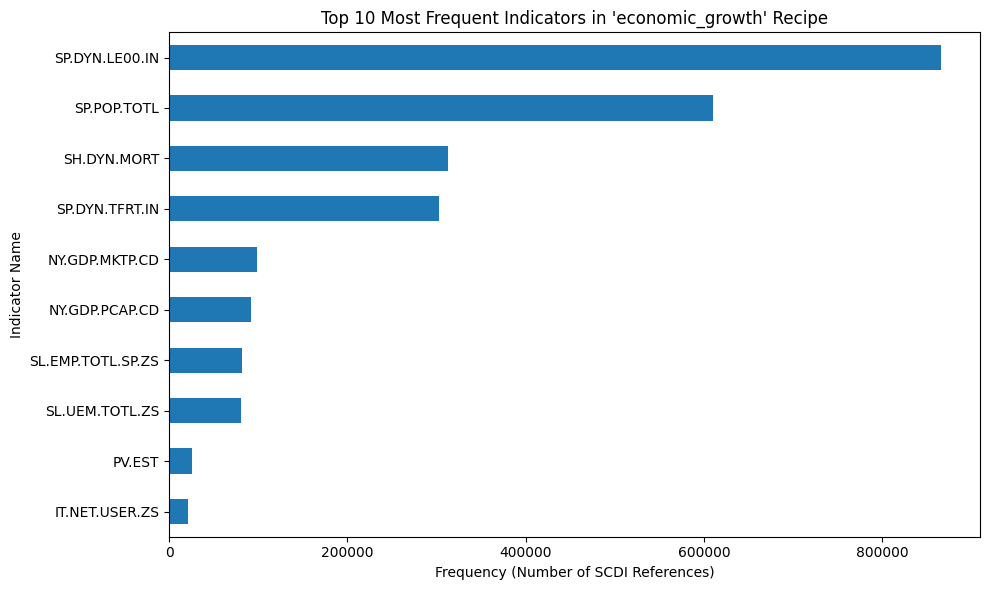

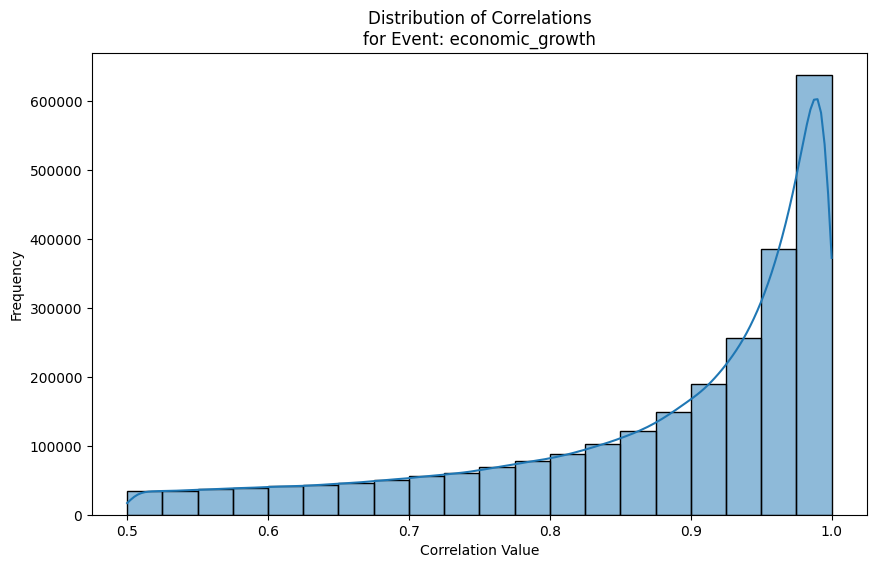

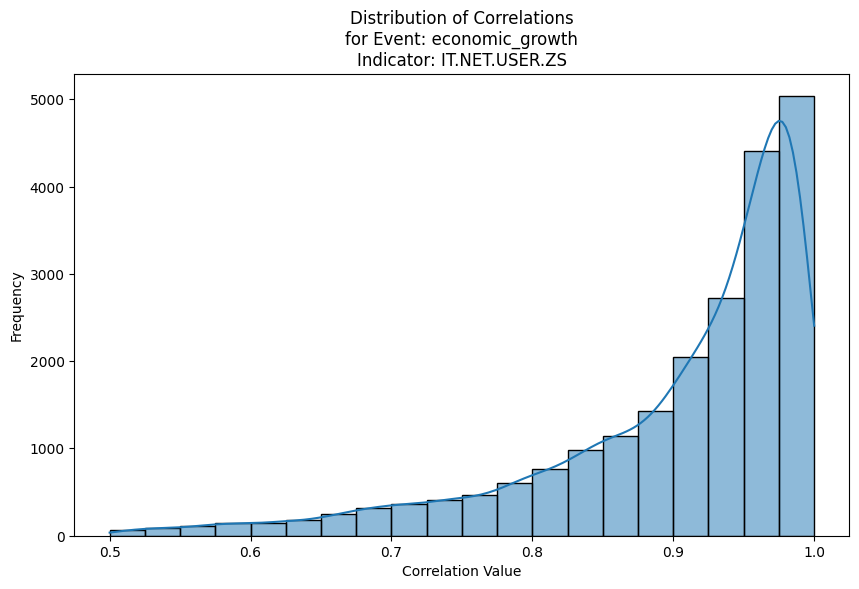

In [5]:
event_to_analyze = "Economic Growth"
summary = analyzer.get_recipe_summary(event_to_analyze, print_summary=True)

#The DataFrame for this specific recipe can be obtained via:
recipe_df = analyzer.load_single_recipe_df(event_to_analyze)
if recipe_df is not None:
    analyzer.plot_indicator_frequency(recipe_df, top_n=10)
    analyzer.plot_correlation_distribution(recipe_df)
    analyzer.plot_correlation_distribution(recipe_df, indicator_name="IT.NET.USER.ZS")

In [6]:
available_event_types = analyzer.get_available_recipes()
print("Available recipe event types:", available_event_types)

Available recipe event types: ['administrative_reform', 'admission_to_asean', 'adoption_of_a_new_constitution', 'adoption_of_the_euro', 'advancements_in_science_and_technology', 'african_swine_fever_outbreak', 'agricultural_crisis', 'agricultural_decline', 'agricultural_development', 'agricultural_development_plan', 'agricultural_development_program', 'agricultural_development_programs', 'agricultural_innovation', 'agricultural_modernization', 'agricultural_policy_changes', 'agricultural_policy_reform', 'agricultural_reform', 'agricultural_reforms', 'agricultural_subsidies', 'air_pollution_crisis', 'airstrikes', 'amnesty_law', 'anti-corruption_campaign', 'anti-corruption_drive', 'anti-corruption_efforts', 'anti-corruption_initiatives', 'anti-corruption_law', 'anti-corruption_legislation', 'anti-corruption_measures', 'anti-discrimination_legislation', 'anti-drug_campaign', 'anti-government_protests', 'anti-poverty_campaign', 'anti-poverty_programs', 'anti-smoking_legislation', 'anti-ter

In [7]:
analyzer.compare_recipes_indicator_overlap("Economic Growth", "Economic Reforms", top_n_indicators=10)


--- Comparison: 'Economic Growth' vs 'Economic Reforms' ---
(Considering Top 10 indicators from each recipe if available)
Indicators in 'Economic Growth': 10
Indicators in 'Economic Reforms': 10
Common Indicators (9): ['SL.UEM.TOTL.ZS', 'NY.GDP.PCAP.CD', 'NY.GDP.MKTP.CD', 'SP.DYN.LE00.IN', 'PV.EST', 'SP.POP.TOTL', 'SH.DYN.MORT', 'SP.DYN.TFRT.IN', 'SL.EMP.TOTL.SP.ZS']
Jaccard Index (Indicator Overlap): 0.8182


{'jaccard_index': 0.8181818181818182,
 'common_indicators': ['SL.UEM.TOTL.ZS',
  'NY.GDP.PCAP.CD',
  'NY.GDP.MKTP.CD',
  'SP.DYN.LE00.IN',
  'PV.EST',
  'SP.POP.TOTL',
  'SH.DYN.MORT',
  'SP.DYN.TFRT.IN',
  'SL.EMP.TOTL.SP.ZS']}

In [8]:
common_inds_df = analyzer.find_common_indicators_across_multiple_recipes(
    event_names_list=["Economic Reforms", "Education Reforms", "Economic Growth"], 
    min_recipe_occurrences=2,
    top_n_per_recipe=5
)
common_inds_df


--- Common Indicators (in at least 2 of the 3 specified recipes) ---
(Considering Top 5 indicators from each recipe if available)
   indicator_name  num_recipes                                      present_in_recipes
0  SP.DYN.LE00.IN            3  [Economic Reforms, Education Reforms, Economic Growth]
1     SP.POP.TOTL            3  [Economic Reforms, Education Reforms, Economic Growth]
2     SH.DYN.MORT            3  [Economic Reforms, Education Reforms, Economic Growth]
3  SP.DYN.TFRT.IN            3  [Economic Reforms, Education Reforms, Economic Growth]
4  NY.GDP.MKTP.CD            2                     [Economic Reforms, Economic Growth]


,indicator_name,num_recipes,present_in_recipes
0,SP.DYN.LE00.IN,3,"[Economic Reforms, Education Reforms, Economic..."
1,SP.POP.TOTL,3,"[Economic Reforms, Education Reforms, Economic..."
2,SH.DYN.MORT,3,"[Economic Reforms, Education Reforms, Economic..."
3,SP.DYN.TFRT.IN,3,"[Economic Reforms, Education Reforms, Economic..."
4,NY.GDP.MKTP.CD,2,"[Economic Reforms, Economic Growth]"


In [11]:
# Find recipes that must include 'EG.ELC.ACCS.UR.ZS' and 'IT.NET.USER.ZS'
search_results_df = analyzer.search_recipes(indicators_must_include=["EG.ELC.ACCS.UR.ZS", "IT.NET.USER.ZS"])
print(search_results_df.iloc[0, 1])
search_results_df

{'EG.ELC.ACCS.UR.ZS': {'present': True}, 'IT.NET.USER.ZS': {'present': True}}


,event_type,details
0,agricultural_reform,"{'EG.ELC.ACCS.UR.ZS': {'present': True}, 'IT.N..."
1,anti-corruption_campaign,"{'EG.ELC.ACCS.UR.ZS': {'present': True}, 'IT.N..."
2,anti-corruption_measures,"{'EG.ELC.ACCS.UR.ZS': {'present': True}, 'IT.N..."
3,constitutional_amendment,"{'EG.ELC.ACCS.UR.ZS': {'present': True}, 'IT.N..."
4,constitutional_referendum,"{'EG.ELC.ACCS.UR.ZS': {'present': True}, 'IT.N..."
...,...,...
154,tourism_development,"{'EG.ELC.ACCS.UR.ZS': {'present': True}, 'IT.N..."
155,tourism_growth,"{'EG.ELC.ACCS.UR.ZS': {'present': True}, 'IT.N..."
156,trade_agreement,"{'EG.ELC.ACCS.UR.ZS': {'present': True}, 'IT.N..."
157,trade_agreements,"{'EG.ELC.ACCS.UR.ZS': {'present': True}, 'IT.N..."


In [ ]:
# Find recipes where 'Albania' was the country of the parquet file origin
# and 'EG.ELC.ACCS.UR.ZS' was an indicator with avg correlation > 0.8 and frequency > 3
complex_search = analyzer.search_recipes(
    country_name_involved='Albania',
    indicators_must_include=['EG.ELC.ACCS.UR.ZS'],
    min_avg_correlation_for_indicator=0.8,
    min_frequency_for_indicator=3
)
complex_search
# Note: The search_recipes logic for combined correlation/frequency checks on specific indicators is a bit complex
# and might need further refinement based on exact query needs. The current version is a starting point.

,event_type,details
0,anti-corruption_efforts,"{'EG.ELC.ACCS.UR.ZS': {'present': True, 'frequ..."
1,covid-19_vaccination,"{'EG.ELC.ACCS.UR.ZS': {'present': True, 'frequ..."
2,economic_growth,"{'EG.ELC.ACCS.UR.ZS': {'present': True, 'frequ..."
3,economic_recovery,"{'EG.ELC.ACCS.UR.ZS': {'present': True, 'frequ..."
4,economic_reforms,"{'EG.ELC.ACCS.UR.ZS': {'present': True, 'frequ..."
5,education_reforms,"{'EG.ELC.ACCS.UR.ZS': {'present': True, 'frequ..."
6,eu_integration,"{'EG.ELC.ACCS.UR.ZS': {'present': True, 'frequ..."
7,eu_integration_progress,"{'EG.ELC.ACCS.UR.ZS': {'present': True, 'frequ..."
8,global_financial_crisis_impact,"{'EG.ELC.ACCS.UR.ZS': {'present': True, 'frequ..."
9,infrastructure_development,"{'EG.ELC.ACCS.UR.ZS': {'present': True, 'frequ..."
